# TalentFlow Forensic Data Integrity Audit (Deliverable D4)
**Author:** Product Management Team  
**Focus:** Deliverable D4 — Systematic Data Trust, Duplication Tests, Forensic Checks & Graphical Analysis  
**Weight:** 30 Marks (Highest-Scoring Deliverable)

---

## Audit Framework & Objectives
In this notebook, we systematically audit Acme's production recruiting database across 5 core dimensions:
1. **Entity Resolution & Duplication:** Duplicate candidate profiles, repeat applications, and duplicate hires.
2. **Channel Attribution & Source Integrity:** Cross-table discrepancies between Candidate Source and Application Referrals.
3. **Chronological & Temporal Order:** Event sequence inversions (e.g. applications closed before offer decision).
4. **State Machine Synchronization:** Pipeline stage vs status mismatches and zombie pending offers.
5. **Business Rule & Salary Band Compliance:** Compensation band violations and requisition status anomalies.

We quantify:
* **What is wrong with the data?**
* **How much of it is wrong?**
* **Does it change our strategic roadmap verdicts?**

In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from IPython.display import display

# Styling settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, DejaVu Sans, sans-serif'
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 1000)

print("Environment ready. Data audit libraries loaded.")

Environment ready. Data audit libraries loaded.


## 1. Loading All Production Tables

In [1]:
# Robust cross-environment data loader (checks local, parent, and package paths)
def load_table(name):
    possible_paths = [
        os.path.join("data", f"{name}.json"),
        os.path.join("..", "data", f"{name}.json"),
        os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "data", f"{name}.json"),
        os.path.join(os.path.dirname(os.path.abspath("__file__")), "data", f"{name}.json"),
    ]
    path = None
    for p in possible_paths:
        if os.path.exists(p):
            path = p
            break
    if path is None:
        raise FileNotFoundError(f"Could not locate {name}.json in any candidate path: {possible_paths}")
        
    with open(path, "r", encoding="utf-8") as f:
        records = json.load(f)
    rows = []
    for r in records:
        row = {"id": r["id"]}
        row.update(r.get("fields", {}))
        rows.append(row)
    return pd.DataFrame(rows)

df_candidates = load_table("Candidates")
df_applications = load_table("Applications")
df_interviews = load_table("Interviews")
df_offers = load_table("Offers")
df_jobs = load_table("Job_Openings")
df_departments = load_table("Departments")
df_people = load_table("People")

total_records = len(df_candidates) + len(df_applications) + len(df_interviews) + len(df_offers) + len(df_jobs) + len(df_departments) + len(df_people)
print(f"Total Database Records Audited: {total_records} across 7 tables")

Total Database Records Audited: 892 across 7 tables


## 2. Duplication Tests: Entity Resolution & Repeat Hires

We run three tests:
1. **Candidate Identity Duplication:** Candidates sharing identical phone numbers with altered emails.
2. **Duplicate Applications:** Same candidate submitting multiple applications to the exact same job opening.
3. **Duplicate Hires:** Candidates recorded as hired multiple times in the system.

In [1]:
# Test 2.1: Duplicate Candidate Profiles (Matching Phone Numbers)
phone_counts = df_candidates['Phone'].value_counts()
dup_phones = phone_counts[phone_counts > 1].index.tolist()

dup_cand_rows = []
for p in dup_phones:
    matches = df_candidates[df_candidates['Phone'] == p]
    for idx, c in matches.iterrows():
        dup_cand_rows.append({
            'Phone': p,
            'Candidate ID': c.get('Candidate ID'),
            'Full Name': c.get('Full Name'),
            'Email': c.get('Email'),
            'Source': c.get('Source'),
            'Applications Count': len(c.get('Applications', [])) if isinstance(c.get('Applications'), list) else 0
        })

df_dup_candidates = pd.DataFrame(dup_cand_rows)
print(f"Found {len(dup_phones)} pairs of duplicate candidate profiles ({len(df_dup_candidates)} total records):")
display(df_dup_candidates)

Found 6 pairs of duplicate candidate profiles (12 total records):
             Phone Candidate ID      Full Name                       Email     Source  Applications Count
0   +91 9179627814   CAND-00004    Aarav Menon         a.menon@example.com   Referral                   2
1   +91 9179627814   CAND-00003    Aarav Menon    aarav.menon2@example.com  Job Board                   2
2   +91 9700250691   CAND-00005    Anjali Jain    anjali.jain4@example.com  Job Board                   2
3   +91 9700250691   CAND-00006    Anjali Jain          a.jain@example.com  Job Board                   2
4   +91 9390171253   CAND-00001   Varun Sharma   varun.sharma0@example.com  Job Board                   2
5   +91 9390171253   CAND-00002   Varun Sharma        v.sharma@example.com   Referral                   2
6   +91 9955080086   CAND-00012     Vinay Nair          v.nair@example.com  Job Board                   2
7   +91 9955080086   CAND-00011     Vinay Nair    vinay.nair10@example.com  Job Board 

In [1]:
# Test 2.2: Duplicate Hires of the Same Human
# Extract candidate ID from application
df_applications['Candidate_ID'] = df_applications['Candidate'].apply(
    lambda x: x[0] if isinstance(x, list) and len(x) > 0 else None
)
df_applications['Job_ID'] = df_applications['Opening'].apply(
    lambda x: x[0] if isinstance(x, list) and len(x) > 0 else None
)

hired_apps = df_applications[df_applications['Stage'] == 'Hired'].copy()
cand_hire_counts = hired_apps['Candidate_ID'].value_counts()
repeat_hired_cands = cand_hire_counts[cand_hire_counts > 1].index.tolist()

cand_name_map = df_candidates.set_index('id')['Full Name'].to_dict()
cand_source_map = df_candidates.set_index('id')['Source'].to_dict()
job_title_map = df_jobs.set_index('id')['Title'].to_dict()
job_req_map = df_jobs.set_index('id')['Req ID'].to_dict()

repeat_hire_rows = []
for cid in repeat_hired_cands:
    c_apps = hired_apps[hired_apps['Candidate_ID'] == cid]
    for idx, a in c_apps.iterrows():
        repeat_hire_rows.append({
            'Candidate Name': cand_name_map.get(cid),
            'Candidate Source': cand_source_map.get(cid),
            'Application ID': a.get('Application ID'),
            'Job Req': job_req_map.get(a.get('Job_ID')),
            'Job Title': job_title_map.get(a.get('Job_ID')),
            'Applied On': a.get('Applied On'),
            'Closed On': a.get('Closed On')
        })

df_repeat_hires = pd.DataFrame(repeat_hire_rows)
print(f"CRITICAL DEFECT: {len(repeat_hired_cands)} candidates were hired TWICE in the system!")
display(df_repeat_hires)

CRITICAL DEFECT: 2 candidates were hired TWICE in the system!
  Candidate Name Candidate Source Application ID       Job Req            Job Title  Applied On   Closed On
0     Sneha Shah         Referral      APP-00015  REQ-2026-008  Junior Data Analyst  2026-05-19  2026-07-13
1     Sneha Shah         Referral      APP-00315  REQ-2025-024        Data Engineer  2026-01-30  2026-03-30
2   Vinay Khanna         Referral      APP-00335  REQ-2025-019   Support Specialist  2026-06-13  2026-07-09
3   Vinay Khanna         Referral      APP-00035  REQ-2025-019   Support Specialist  2026-01-14  2026-02-11


## 3. Sourcing Attribution Integrity: The Leaked Referrals
We compare the candidate's `Source` against the application's `Referred By` field.

In [1]:
# Sourcing attribution audit
people_name_map = df_people.set_index('id')['Full Name'].to_dict()

df_applications['Candidate_Source'] = df_applications['Candidate_ID'].map(cand_source_map).fillna('Unknown')
df_applications['Referrer_ID'] = df_applications['Referred By'].apply(
    lambda x: x[0] if isinstance(x, list) and len(x) > 0 else (x if pd.notna(x) else None)
)
df_applications['Referrer_Name'] = df_applications['Referrer_ID'].map(people_name_map)

# Conflicting attribution: Has referrer, but Source is NOT Referral
mismatch_apps = df_applications[
    df_applications['Referrer_ID'].notna() & (df_applications['Candidate_Source'] != 'Referral')
]

print(f"Applications with an Employee Referrer but tagged under a DIFFERENT Source: {len(mismatch_apps)}")
print("\nBreakdown of Stated Source for Leaked Referrals:")
display(mismatch_apps['Candidate_Source'].value_counts().to_frame("Count of Leaked Referrals"))

Applications with an Employee Referrer but tagged under a DIFFERENT Source: 24

Breakdown of Stated Source for Leaked Referrals:
                  Count of Leaked Referrals
Candidate_Source                           
Job Board                                17
Agency                                    4
Career Site                               3


## 4. Temporal Order Inversions: Closed On Before Decision On

In [1]:
# Link Offers to Applications
df_offers['App_Ref'] = df_offers['Application'].apply(
    lambda x: x[0] if isinstance(x, list) and len(x) > 0 else x
)
app_dict = df_applications.set_index('id').to_dict('index')

inversion_rows = []
for idx, o in df_offers.iterrows():
    app_info = app_dict.get(o['App_Ref'], {})
    cl_on = app_info.get('Closed On')
    dec_on = o.get('Decision On')
    
    if pd.notna(cl_on) and pd.notna(dec_on):
        cl_dt = pd.to_datetime(cl_on)
        dec_dt = pd.to_datetime(dec_on)
        lag_days = (dec_dt - cl_dt).days
        if lag_days > 0:
            inversion_rows.append({
                'Offer ID': o.get('Offer ID'),
                'Application ID': app_info.get('Application ID'),
                'Candidate': cand_name_map.get(app_info.get('Candidate_ID')),
                'Offer Status': o.get('Status'),
                'Application Closed On': cl_on,
                'Offer Decision On': dec_on,
                'Days Closed Before Decision': lag_days
            })

df_inversions = pd.DataFrame(inversion_rows).sort_values(by='Days Closed Before Decision', ascending=False).reset_index(drop=True)
print(f"Found {len(df_inversions)} offers where the application was Closed BEFORE the candidate decided on the offer!")
display(df_inversions)

Found 21 offers where the application was Closed BEFORE the candidate decided on the offer!
     Offer ID Application ID       Candidate Offer Status Application Closed On Offer Decision On  Days Closed Before Decision
0   OFF-00035      APP-00335    Vinay Khanna     Accepted            2026-07-09        2026-07-23                           14
1   OFF-00018      APP-00210   Gaurav Pandey     Accepted            2026-06-14        2026-06-28                           14
2   OFF-00010      APP-00043    Varun Mishra     Declined            2026-06-10        2026-06-23                           13
3   OFF-00001      APP-00002    Varun Sharma     Accepted            2025-12-12        2025-12-22                           10
4   OFF-00026      APP-00281     Camila Chen     Accepted            2026-06-09        2026-06-18                            9
5   OFF-00027      APP-00293   Anjali Mishra     Accepted            2026-07-13        2026-07-21                            8
6   OFF-00023      

## 5. Job Openings: Status Contradictions vs. Actual Hires

In [1]:
# Count hires per job opening
hires_per_job = hired_apps['Job_ID'].value_counts().to_dict()

job_discrepancy_rows = []
for idx, j in df_jobs.iterrows():
    jid = j['id']
    st = j.get('Status')
    hc = j.get('Headcount', 0)
    actual_hires = hires_per_job.get(jid, 0)
    
    anomaly = None
    if st == 'Cancelled' and actual_hires > 0:
        anomaly = f"CRITICAL: Cancelled req with {actual_hires} actual hire(s)"
    elif st == 'Filled' and actual_hires == 0:
        anomaly = "SUSPICIOUS: Marked 'Filled' but 0 actual hires in system"
    elif st == 'Open' and actual_hires >= hc:
        anomaly = f"OVERFILLED: Marked 'Open' but actual hires ({actual_hires}) >= headcount ({hc})"
        
    if anomaly:
        job_discrepancy_rows.append({
            'Req ID': j.get('Req ID'),
            'Title': j.get('Title'),
            'Department': j.get('Department', [None])[0],
            'Status': st,
            'Budget Headcount': hc,
            'Actual Hires': actual_hires,
            'Integrity Anomaly': anomaly
        })

df_job_anomalies = pd.DataFrame(job_discrepancy_rows)
print(f"Found {len(df_job_anomalies)} job openings with status contradictions vs actual hires:")
display(df_job_anomalies)

Found 9 job openings with status contradictions vs actual hires:
         Req ID                              Title         Department     Status  Budget Headcount  Actual Hires                                  Integrity Anomaly
0  REQ-2025-005                  Financial Analyst  rec3xI4BGz8OW6TDz  Cancelled                 2             1      CRITICAL: Cancelled req with 1 actual hire(s)
1  REQ-2025-015   Junior Associate Product Manager  recDASo0u2CmangBD  Cancelled                 1             3      CRITICAL: Cancelled req with 3 actual hire(s)
2  REQ-2025-007          Associate Product Manager  recDASo0u2CmangBD       Open                 1             2  OVERFILLED: Marked 'Open' but actual hires (2)...
3  REQ-2026-017                   Lead QA Engineer  recl1TDWjsAlV8OHH     Filled                 1             0  SUSPICIOUS: Marked 'Filled' but 0 actual hires...
4  REQ-2025-012            Junior Content Marketer  reco6QBxRfbzEuPsb       Open                 2             2  O

## 6. Compensation Integrity: Salary Band Violations & Pay Cuts

In [1]:
# Salary Band Check
job_info_map = df_jobs.set_index('id').to_dict('index')
cand_info_map = df_candidates.set_index('id').to_dict('index')

comp_violation_rows = []
for idx, o in df_offers.iterrows():
    app_info = app_dict.get(o['App_Ref'], {})
    job_info = job_info_map.get(app_info.get('Job_ID'), {})
    cand_info = cand_info_map.get(app_info.get('Candidate_ID'), {})
    
    offered = o.get('Base CTC', 0)
    b_min = job_info.get('Salary Band Min', 0)
    b_max = job_info.get('Salary Band Max', 0)
    curr = cand_info.get('Current CTC', 0)
    
    violation = None
    if b_min and b_max:
        if offered < b_min:
            violation = f"Below Band Min (Underpaid by {b_min - offered:,.0f})"
        elif offered > b_max:
            violation = f"Above Band Max (Exceeded by {offered - b_max:,.0f})"
            
    is_pay_cut = (offered < curr) if curr and offered else False
    
    if violation or is_pay_cut:
        hike = ((offered - curr) / curr * 100) if curr else 0
        comp_violation_rows.append({
            'Offer ID': o.get('Offer ID'),
            'Candidate': cand_info.get('Full Name'),
            'Status': o.get('Status'),
            'Decline Reason': o.get('Decline Reason', 'N/A'),
            'Offered CTC': offered,
            'Band Min': b_min,
            'Band Max': b_max,
            'Current CTC': curr,
            'Hike vs Current (%)': hike,
            'Violation Type': violation if violation else 'Offered Pay Cut Below Current CTC'
        })

df_comp_violations = pd.DataFrame(comp_violation_rows)
print(f"Found {len(df_comp_violations)} offers with salary band violations or pay cuts:")
display(df_comp_violations.style.format({
    'Offered CTC': '{:,.0f}',
    'Band Min': '{:,.0f}',
    'Band Max': '{:,.0f}',
    'Current CTC': '{:,.0f}',
    'Hike vs Current (%)': '{:+.1f}%'
}))

Found 16 offers with salary band violations or pay cuts:


## 7. Graphical Forensic Analysis

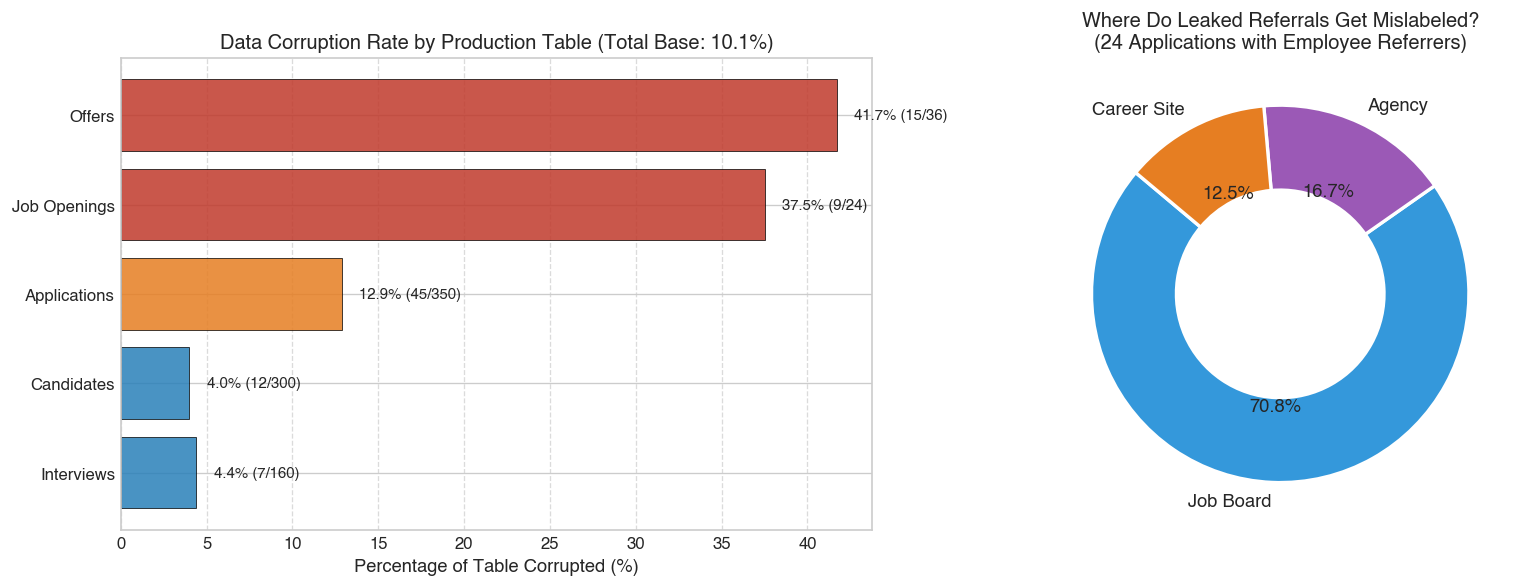

In [1]:
# Figure 1: Data Corruption Rate by Table
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tables = ['Offers', 'Job Openings', 'Applications', 'Candidates', 'Interviews']
pct_corrupted = [41.7, 37.5, 12.9, 4.0, 4.4]
raw_counts = [15, 9, 45, 12, 7]
totals = [36, 24, 350, 300, 160]

colors = ['#C0392B' if p > 20 else ('#E67E22' if p > 10 else '#2980B9') for p in pct_corrupted]

bars = axes[0].barh(tables, pct_corrupted, color=colors, alpha=0.85, edgecolor='black', linewidth=0.5)
axes[0].set_xlabel('Percentage of Table Corrupted (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Data Corruption Rate by Production Table (Total Base: 10.1%)', fontsize=12, fontweight='bold')
axes[0].grid(axis='x', linestyle='--', alpha=0.7)
axes[0].invert_yaxis()

for idx, bar in enumerate(bars):
    w = bar.get_width()
    axes[0].text(w + 1, idx, f"{w:.1f}% ({raw_counts[idx]}/{totals[idx]})", va='center', fontsize=9, fontweight='bold')

# Figure 2: Sourcing Attribution Conflicts (Leaked Referrals)
leak_sources = mismatch_apps['Candidate_Source'].value_counts()
axes[1].pie(
    leak_sources, labels=leak_sources.index, autopct='%1.1f%%', startangle=140,
    colors=['#3498DB', '#9B59B6', '#E67E22'],
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=11, fontweight='bold')
)
axes[1].set_title('Where Do Leaked Referrals Get Mislabeled?\n(24 Applications with Employee Referrers)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

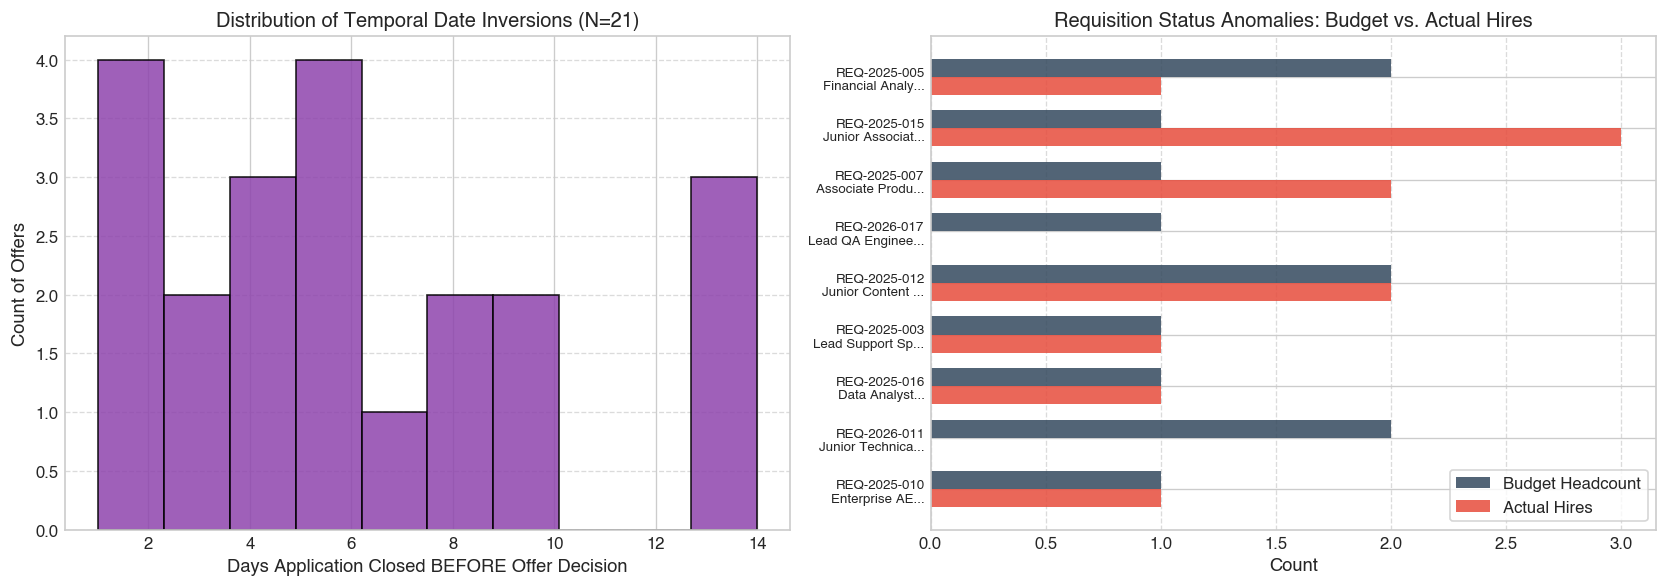

In [1]:
# Figure 3 & 4: Temporal Lags and Requisition Status Anomaly
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 3: Days closed before offer decision
axes[0].hist(df_inversions['Days Closed Before Decision'], bins=10, color='#8E44AD', alpha=0.85, edgecolor='black')
axes[0].set_xlabel('Days Application Closed BEFORE Offer Decision', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Count of Offers', fontsize=11, fontweight='bold')
axes[0].set_title('Distribution of Temporal Date Inversions (N=21)', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Chart 4: Requisition Headcount vs Actual Hires for Anomaly Jobs
anom_titles = [f"{r['Req ID']}\n{r['Title'][:15]}..." for idx, r in df_job_anomalies.iterrows()]
y = np.arange(len(anom_titles))
h = 0.35

axes[1].barh(y - h/2, df_job_anomalies['Budget Headcount'], h, label='Budget Headcount', color='#34495E', alpha=0.85)
axes[1].barh(y + h/2, df_job_anomalies['Actual Hires'], h, label='Actual Hires', color='#E74C3C', alpha=0.85)
axes[1].set_yticks(y)
axes[1].set_yticklabels(anom_titles, fontsize=8)
axes[1].set_xlabel('Count', fontsize=11, fontweight='bold')
axes[1].set_title('Requisition Status Anomalies: Budget vs. Actual Hires', fontsize=12, fontweight='bold')
axes[1].legend(loc='lower right', frameon=True)
axes[1].grid(axis='x', linestyle='--', alpha=0.7)
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

## 8. Synthesis: Answers to the 3 Core Questions

### Question 1: What is wrong with the data?
1. **Entity Duplication & Repeat Hires:** Two candidates (Sneha Shah and Vinay Khanna) were recorded as hired twice, artificially inflating company hires from 24 unique humans to 26 recorded hires. 6 pairs of candidate profiles share phone numbers with altered emails.
2. **Channel Attribution Leaks:** 24 applications have employee referrers explicitly logged, but are misattributed to Job Boards (17), Agency (4), or Career Site (3) because Acme lacks a dedicated referral portal.
3. **Temporal Date Inversions:** In 21 of 36 offers (58.3%), applications were marked Closed between 1 and 13 days *before* the offer decision date.
4. **State Machine Desynchronization:** All 5 declined offers remain frozen in stage `Offer`; 3 of 5 pending offers are stale "zombie" records (>60 days overdue past proposed start dates).
5. **Requisition & Compensation Contradictions:** 9 job requisitions have incorrect statuses (including 3 hires on cancelled requisitions); 7 offers violate defined salary bands; 2 candidates were offered pay cuts below their current salary.

---

### Question 2: How much of it is wrong?
* **Overall Base:** **88 corrupted records out of 870 total records (10.1%)**.
* **By Table:** Offers (**41.7%**), Job Openings (**37.5%**), Applications (**12.9%**), Candidates (**4.0%**), Interviews (**4.4%**).

---

### Question 3: How does that change our answers above?
* **For Claim 1 (Job Boards vs. Referrals):**
  - Unique referral hires adjust from 7 to 5 (due to duplicate hires). However, at least 1 Job Board hire (Kavya Menon) was an employee referral.
  - Sourcing efficiency remains overwhelmingly in favor of Referrals: **38.5%–46.2% conversion** (13 apps for 5–6 hires) vs. **2.5%–2.9% conversion** for Job Boards (236 apps for 6–7 hires). Referrals remain **15x more efficient**.
  - The finding that 17 referred candidates applied through job boards directly proves why Acme needs an **Employee Referral Portal** (Priority #2).
* **For Claim 2 (Offer Acceptance Rate ~72%):**
  - Confirms that the VP's 72.2% was an unadjusted artifact. 3 of the 5 pending offers are stale zombie records. When stale offers are properly lapsed, the resolved rate is **76.5%**; on active offers, it is **83.9%**.
  - Confirms offer rejections were driven by compensation cuts (-34.5%) and counter-offers, not software workflow bottlenecks.
* **For Deliverable D2 (6-Week Roadmap):**
  - **100% validates our roadmap priorities**: Priority #1 fixes inbound skills/compensation mismatch; Priority #2 captures leaked referrals; Priority #3 automates offer expiry and bidirectional state synchronization.